# 用 Transformer 搭一台 CPU

这台 16 位、4 寄存器、9 条指令的小 CPU **完全由一个 Transformer 实现**：权重是手工写入的，网络里只有 `nn.Linear`、ReLU、hardmax attention 和残差连接。

- 一次前向传播 = 执行一条指令；
- 外层循环只做 `x = model(x)`；
- 每一步的结果与普通 Python 参考 CPU **比特级一致**。

理论背景：Pérez et al.《Attention is Turing Complete》；Giannou et al. 2023《Looped Transformers as Programmable Computers》。

In [1]:
import torch, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from tfcpu import assemble, build_cpu, run, run_ref, encode, decode, LAYOUT
from tfcpu.state import CPU, PROG0, MEM0
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang SC", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

model = build_cpu()
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nd_model = {LAYOUT.d}, 序列长度 = 129 个 token, 参数量 = {n_params:,}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


LoopedTransformer(
  (blocks): ModuleList(
    (0): Block(
      (attn): HardmaxAttention(
        (q): Linear(in_features=74, out_features=3, bias=False)
        (k): Linear(in_features=74, out_features=3, bias=False)
        (v): Linear(in_features=74, out_features=22, bias=False)
        (o): Linear(in_features=22, out_features=74, bias=False)
      )
      (mlp): MLP(
        (fc1): Linear(in_features=74, out_features=16, bias=True)
        (act): ReLU()
        (fc2): Linear(in_features=16, out_features=74, bias=True)
      )
    )
    (1): Block(
      (attn): HardmaxAttention(
        (q): Linear(in_features=74, out_features=3, bias=False)
        (k): Linear(in_features=74, out_features=3, bias=False)
        (v): Linear(in_features=74, out_features=1, bias=False)
        (o): Linear(in_features=1, out_features=74, bias=False)
      )
      (mlp): MLP(
        (fc1): Linear(in_features=74, out_features=23, bias=True)
        (act): ReLU()
        (fc2): Linear(in_features=23, o

## 1. 跑一个冒泡排序

In [2]:
src = Path("../examples/bubble_sort.asm").read_text()
print(src)
prog = assemble(src)
trace = run(model, prog, max_steps=5000)
print("步数:", trace.steps, " 停机:", trace.final.halted)
print("排序前:", list(prog.mem[:8]))
print("排序后:", list(trace.final.mem[:8]))

; Bubble sort M[0..7] ascending. M[63] holds the outer pass counter (n - 1).
outer:  LOADI r0, 0          ; j = 0
inner:  LOAD  r1, r0, 0      ; x = M[j]
        LOAD  r2, r0, 1      ; y = M[j+1]
        SUB   r3, r2, r1     ; y - x
        JNEG  r3, swap       ; y < x  ->  swap
next:   LOADI r3, 1
        ADD   r0, r0, r3     ; j += 1
        LOADI r3, 7
        SUB   r3, r0, r3     ; j - 7
        JNEG  r3, inner
        LOAD  r1, r0, 56     ; j == 7 here, so this is M[63]
        LOADI r3, 1
        SUB   r1, r1, r3
        STORE r1, r0, 56
        JZ    r1, done
        JMP   outer
done:   HALT
swap:   STORE r2, r0, 0
        STORE r1, r0, 1
        JMP   next

.data 0  5 -3 12 0 7 7 -20 4
.data 63 7



步数: 535  停机: True
排序前: [5, -3, 12, 0, 7, 7, -20, 4]
排序后: [-20, -3, 0, 4, 5, 7, 7, 12]


## 2. 与参考 CPU 逐步对比

In [3]:
ref = run_ref(prog, max_steps=5000)
same = sum(a == b for a, b in zip(trace.states, ref))
print(f"{same} / {len(ref)} 个状态完全一致" + (" ✓" if trace.states == ref else " ✗"))

536 / 536 个状态完全一致 ✓


## 3. 权重长什么样

每个 MLP 隐藏单元都是一个 ReLU 积木（门控、判零、回绕……）。下面是 B4（写回）的第一层权重：行是隐藏单元，列是残差流里有名字的维度。颜色用 `sign(w)·log10(1+|w|)`，大常数 M = 2²⁰ 是门控用的。

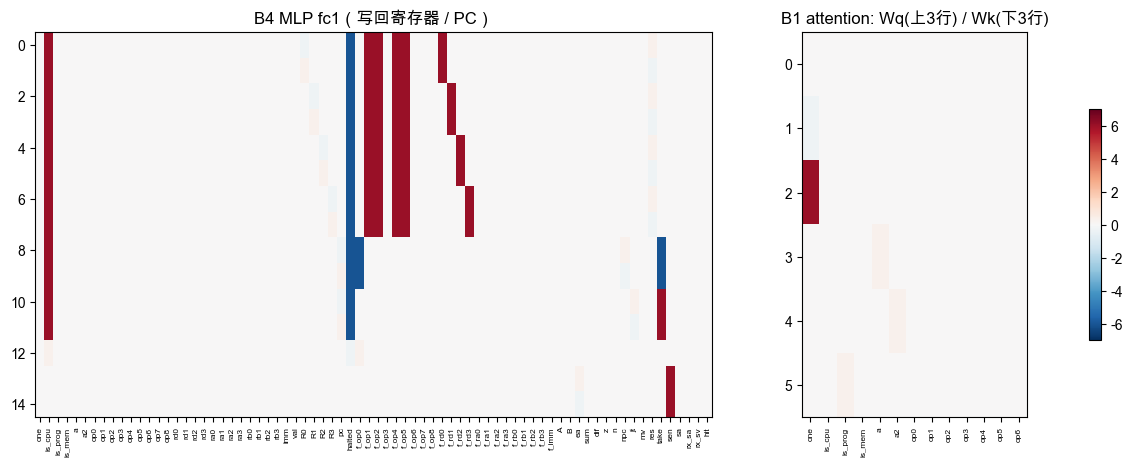

In [4]:
def show(W, xlabels, title, ax):
    W = W.numpy()
    im = ax.imshow(np.sign(W) * np.log10(1 + np.abs(W)), cmap="RdBu_r", vmin=-7, vmax=7, aspect="auto")
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels, rotation=90, fontsize=6)
    ax.set_title(title); return im

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [3, 1]})
b4 = model.blocks[3]
im = show(b4.mlp.fc1.weight, LAYOUT.names, "B4 MLP fc1（写回寄存器 / PC）", axes[0])
b1 = model.blocks[0].attn
show(torch.cat([b1.q.weight, b1.k.weight]), LAYOUT.names, "B1 attention: Wq(上3行) / Wk(下3行)", axes[1])
axes[1].set_xlim(-0.5, 12.5)
fig.colorbar(im, ax=axes, shrink=0.6); plt.show()

## 4. 看 attention 在做什么

取第 30 步的状态，执行一次前向，记录 B1（取指）和 B3（读内存）里 CPU token 的注意力：hardmax 恰好落在一个 token 上。

PC = 6, 寄存器 = (2, 12, 0, 1)
B1 取指: CPU 注意力 100% 落在 token 7 = PROG[6] -> ADD   r0, r0, r3
B3 读存: CPU 注意力 100% 落在 token 67 = MEM[2] = 0
下一状态与参考一致: True


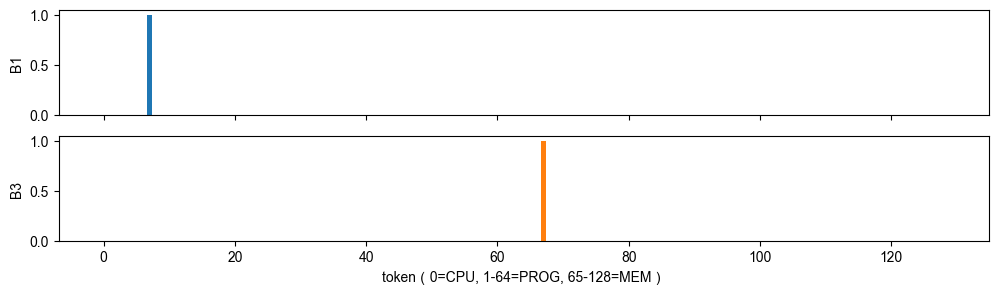

In [5]:
s = trace.states[30]
for blk in model.blocks: blk.attn.record = True
with torch.no_grad(): y = model(encode(s))
for blk in model.blocks: blk.attn.record = False

w1 = model.blocks[0].attn.last_weights[CPU]
w3 = model.blocks[2].attn.last_weights[CPU]
t1, t3 = int(w1.argmax()), int(w3.argmax())
print(f"PC = {s.pc}, 寄存器 = {s.regs}")
print(f"B1 取指: CPU 注意力 100% 落在 token {t1} = PROG[{t1 - PROG0}] -> {s.program[t1 - PROG0]}")
print(f"B3 读存: CPU 注意力 100% 落在 token {t3} = MEM[{t3 - MEM0}] = {s.mem[t3 - MEM0]}")
print("下一状态与参考一致:", decode(y) == trace.states[31])

fig, ax = plt.subplots(2, 1, figsize=(12, 3), sharex=True)
ax[0].bar(range(129), w1.numpy()); ax[0].set_ylabel("B1")
ax[1].bar(range(129), w3.numpy(), color="C1"); ax[1].set_ylabel("B3")
ax[1].set_xlabel("token（0=CPU, 1-64=PROG, 65-128=MEM）"); plt.show()

## 5. 寄存器和 PC 随时间变化

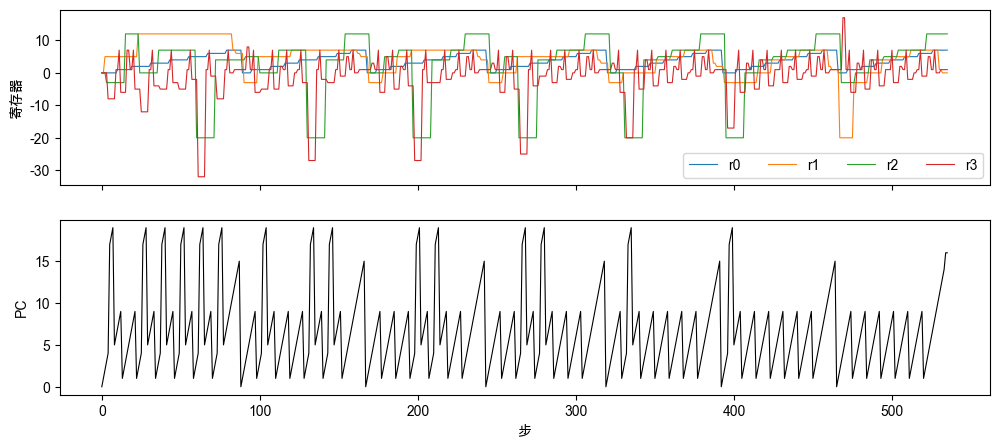

In [6]:
regs = np.array([st.regs for st in trace.states]); pcs = [st.pc for st in trace.states]
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for i in range(4): ax[0].plot(regs[:, i], label=f"r{i}", lw=0.8)
ax[0].legend(ncol=4); ax[0].set_ylabel("寄存器")
ax[1].plot(pcs, lw=0.8, color="k"); ax[1].set_ylabel("PC"); ax[1].set_xlabel("步")
plt.show()

## 6. 写你自己的程序

指令：`LOADI rd, imm` · `LOAD rd, ra, imm` · `STORE rs, ra, imm` · `ADD/SUB rd, ra, rb` · `JZ/JNEG ra, label` · `JMP label` · `HALT`；`.data addr v1 v2 ...` 初始化内存。地址与跳转目标夹取到 0–63，算术 16 位回绕。

In [7]:
my = assemble('''
        LOADI r0, 30000
        LOADI r1, 10000
        ADD   r2, r0, r1     ; 40000 -> 回绕成 -25536
        STORE r2, r3, 0
        HALT
''')
t = run(model, my)
print(t.final.regs, t.final.mem[0], "| 参考一致:", t.states == run_ref(my))

(30000, 10000, -25536, 0) -25536 | 参考一致: True
